# Sprint 05 - Fairness

## Sistema de Inteligencia Tributaria - Palmas/TO
**Responsavel:** Arthur Felipe

Avaliacao experimental de equidade algoritmica.

Os alvos utilizados sao sinteticos. Os resultados nao
comprovam equidade demografica real e nao autorizam
decisoes tributarias individualizadas.


## 1. Configuracao do ambiente

In [1]:
import sys
import json
import subprocess
from pathlib import Path

import pandas as pd
from IPython.display import display, Image

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/governance/fairness.py").exists()
)

OUTPUT = ROOT / "docs/evidencias/fairness"

print("Projeto:", ROOT)
print("Python:", sys.version)


Projeto: .
Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


## 2. Reproducao dos experimentos

Os modelos existentes sao avaliados sem retreinamento.


In [2]:
for modulo in [
    "src.analysis.fairness_experimento",
    "src.analysis.fairness_evidencias",
]:
    processo = subprocess.run(
        [sys.executable, "-m", modulo],
        cwd=ROOT,
        capture_output=True,
        text=True,
        encoding="utf-8",
        env={**__import__("os").environ, "PYTHONUTF8": "1"},
    )

    if processo.returncode != 0:
        raise RuntimeError(processo.stderr)

    print(modulo, "- OK")


src.analysis.fairness_experimento - OK


src.analysis.fairness_evidencias - OK


## 3. Caracterizacao da amostra

In [3]:
relatorio = json.loads(
    (OUTPUT / "metricas_modelos_proxy.json").read_text(
        encoding="utf-8"
    )
)

display(pd.DataFrame({
    "Indicador": [
        "Registros validos",
        "Registros de teste",
        "Matrizes originais reproduzidas",
    ],
    "Resultado": [
        relatorio["registros_validos"],
        relatorio["registros_teste"],
        relatorio["matrizes_originais_reproduzidas"],
    ],
}))


,Indicador,Resultado
0,Registros validos,38557
1,Registros de teste,11048
2,Matrizes originais reproduzidas,True


## 4. Metricas de disparidade

DP: diferenca entre taxas de selecao.

EO: diferenca entre taxas de verdadeiros positivos.

DI: razao entre a menor e a maior taxa de selecao.

Valores indefinidos sao preservados como ausentes.


In [4]:
linhas = []

for modelo, dimensoes in relatorio["modelos"].items():
    for dimensao, resultado in dimensoes.items():
        linhas.append({
            "Modelo": modelo,
            "Dimensao": dimensao,
            "DP": resultado["demographic_parity_difference"],
            "EO": resultado["equal_opportunity_difference"],
            "DI": resultado["disparate_impact_ratio"],
            "FPR Difference": resultado[
                "false_positive_rate_difference"
            ],
        })

display(pd.DataFrame(linhas).round(4))


,Modelo,Dimensao,DP,EO,DI,FPR Difference
0,regressao_logistica,faixa_valor,1.0000,1.0000,0.0000,1.0000
1,regressao_logistica,faixa_idade,0.3529,NaN,0.2942,0.3792
2,arvore_decisao,faixa_valor,0.7980,0.8217,0.0039,0.7907
3,arvore_decisao,faixa_idade,0.2341,NaN,0.5318,0.2620
4,random_forest_inadimplencia,faixa_valor,0.7405,0.7203,0.0000,0.7550
5,random_forest_inadimplencia,faixa_idade,0.3864,NaN,0.2272,0.4054
6,recuperabilidade_baixa,faixa_valor,0.5131,NaN,0.0000,0.4201
7,recuperabilidade_baixa,faixa_idade,0.0159,NaN,0.0000,0.0110
8,recuperabilidade_media,faixa_valor,0.5131,0.4201,0.4869,NaN
9,recuperabilidade_media,faixa_idade,0.1791,0.0139,0.8209,NaN


## 5. Comparacao dos modelos de inadimplencia

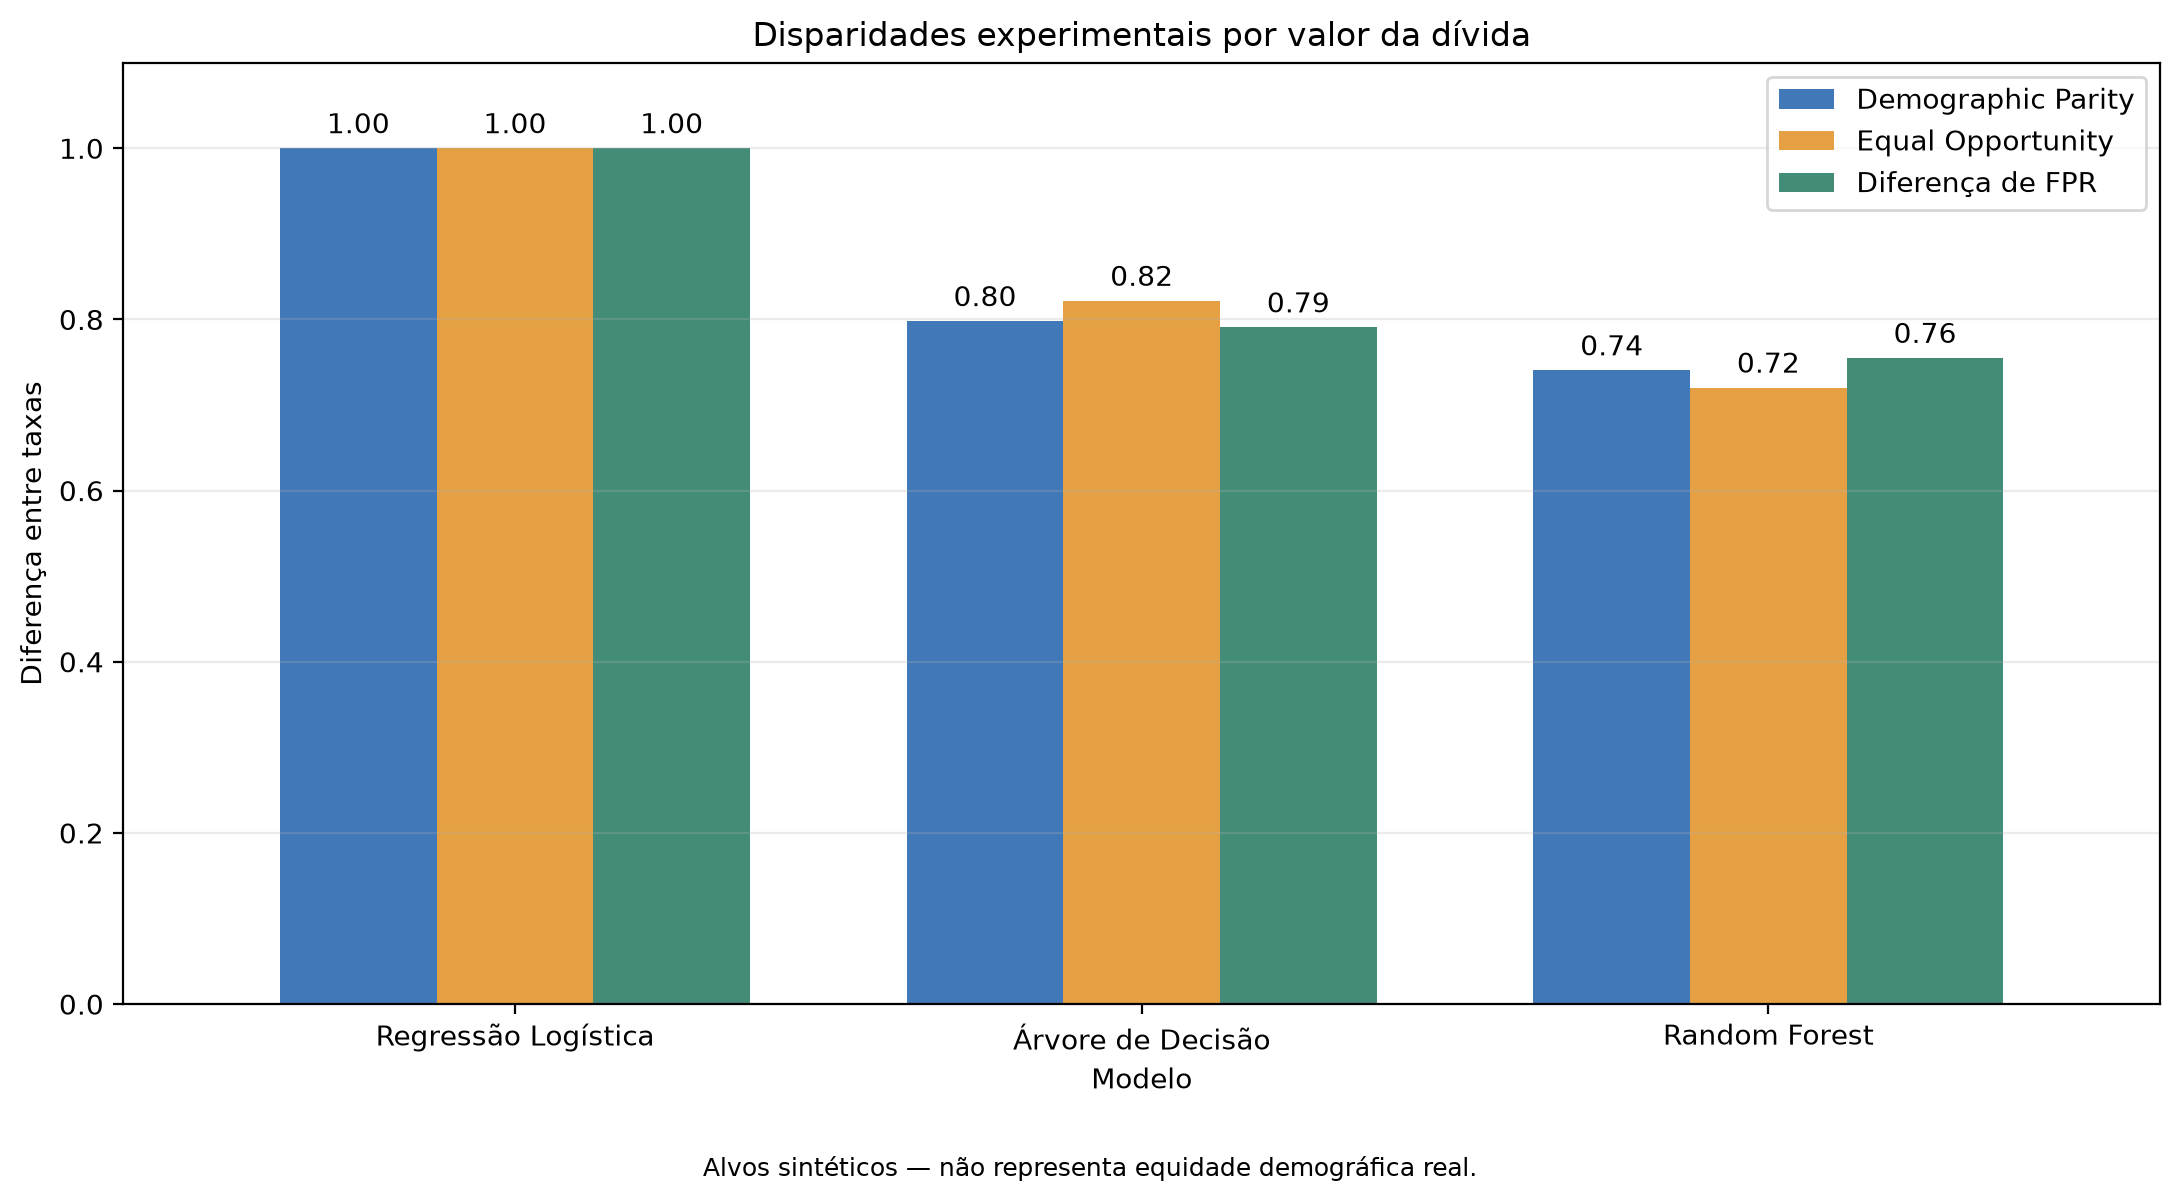

In [5]:
display(Image(filename=str(
    OUTPUT / "01_comparacao_modelos.png"
)))


## 6. Random Forest por faixa de valor

,grupo,n,tp,tn,fp,fn,taxa_selecao,tpr,fpr,fnr,precisao,acuracia
0,500_a_5000,3409,278,1890,724,517,0.2939,0.3497,0.277,0.6503,0.2774,0.6360
1,acima_5000,343,103,49,151,40,0.7405,0.7203,0.755,0.2797,0.4055,0.4431
2,ate_500,7296,0,6431,0,865,0.0000,0.0000,0.000,1.0000,NaN,0.8814


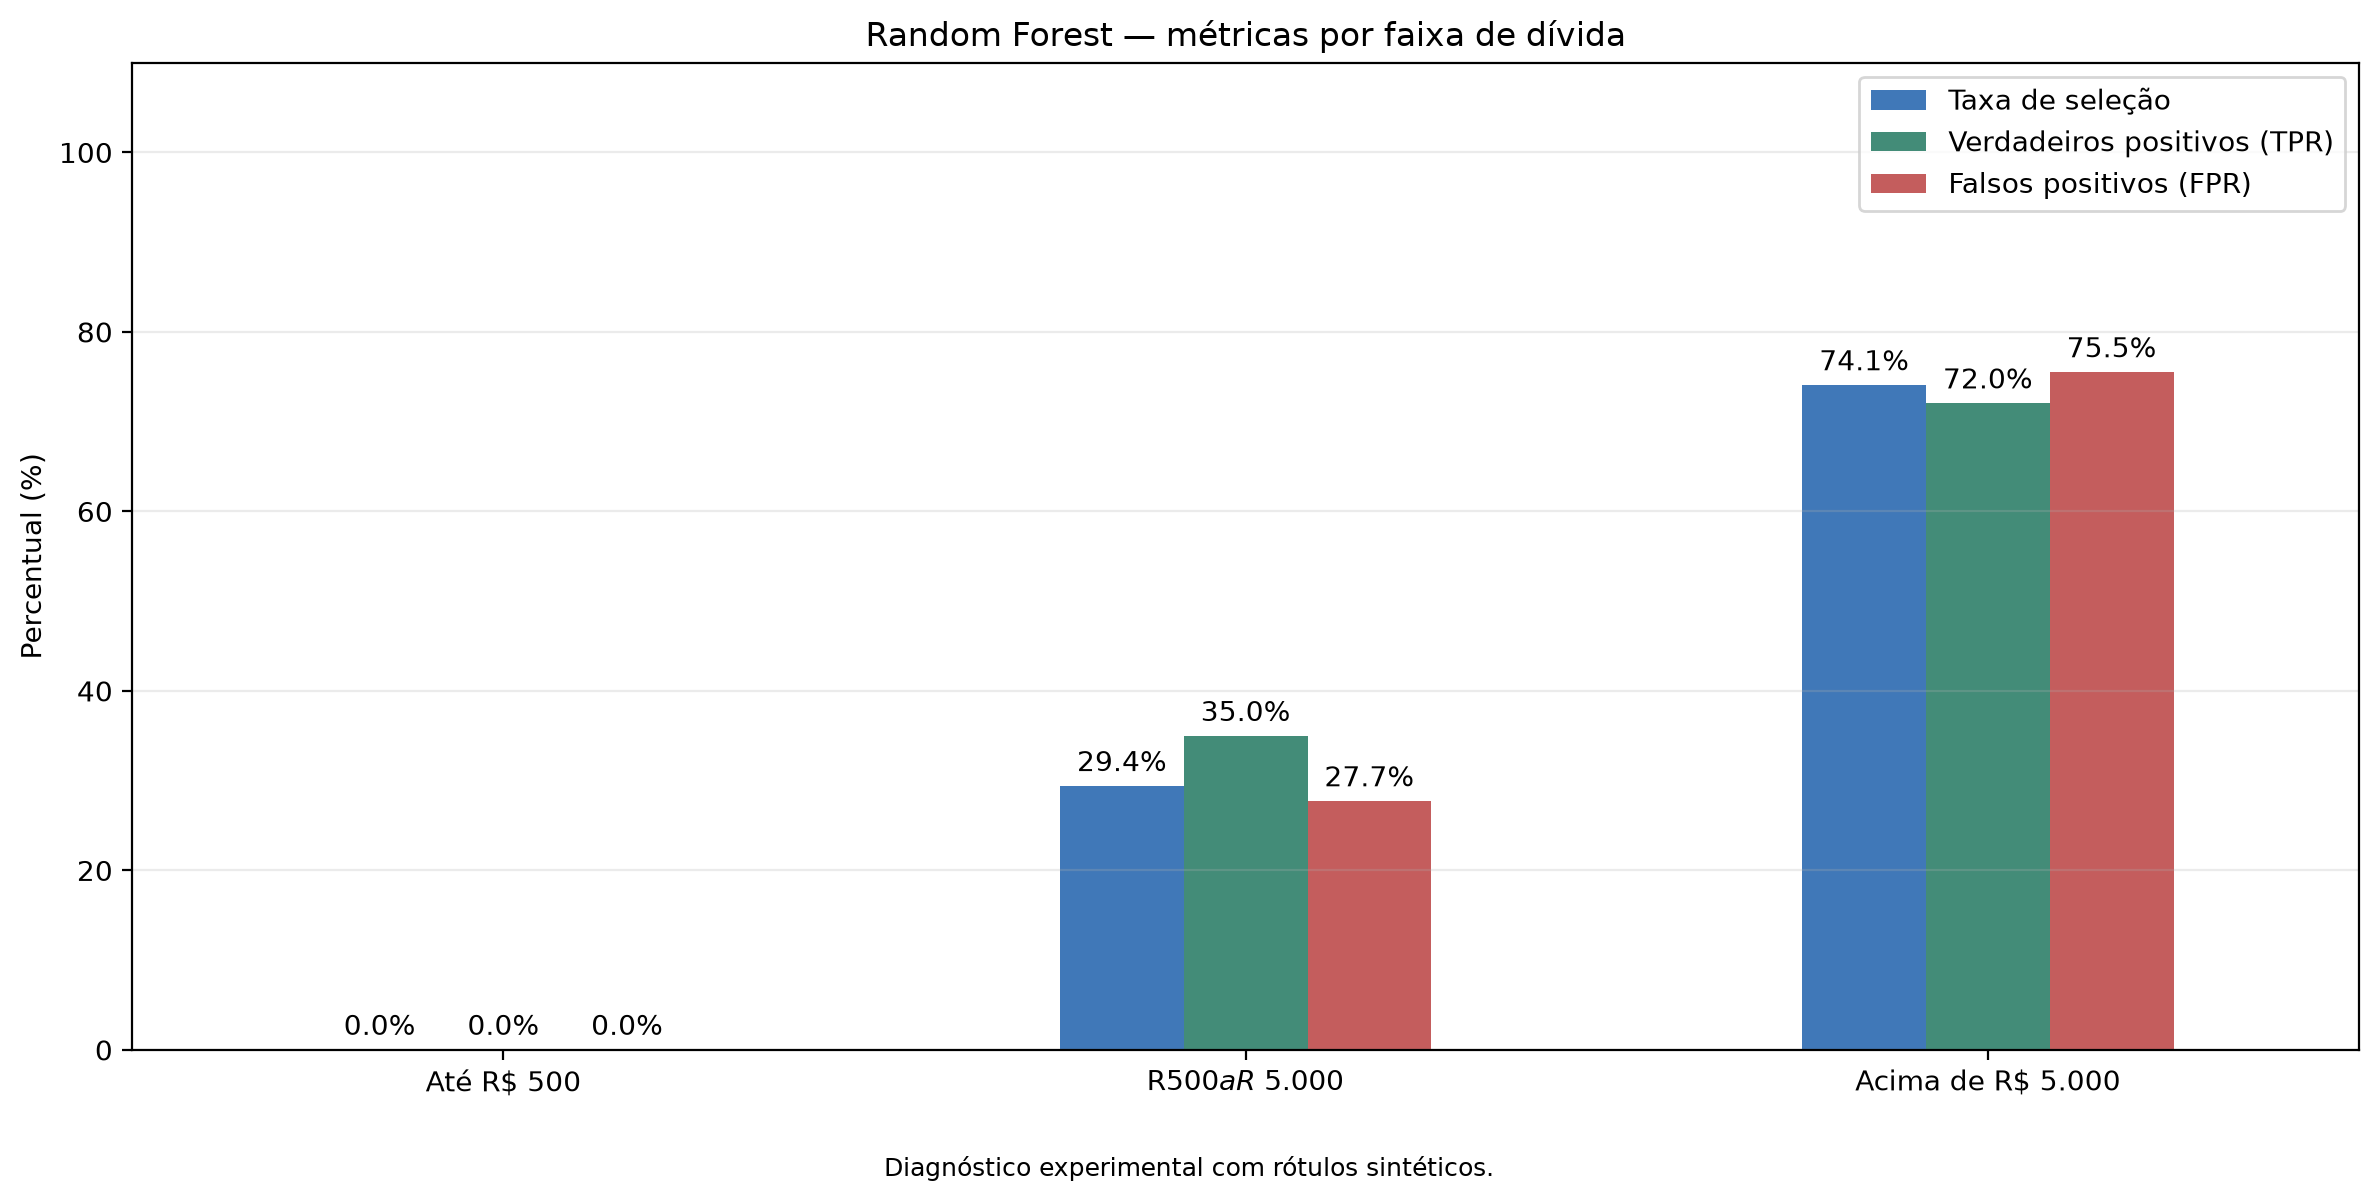

In [6]:
dados = relatorio["modelos"][
    "random_forest_inadimplencia"
]["faixa_valor"]["grupos"]

display(pd.DataFrame(dados).round(4))

display(Image(filename=str(
    OUTPUT / "02_random_forest_subgrupos.png"
)))


## 7. Cenarios integralmente sinteticos

,Cenario,DP,EO,DI
0,paridade,0.0,0.0,1.0000
1,disparidade,0.5,0.5,0.3333
2,paridade_selecao_sem_equal_opportunity,0.0,1.0,1.0000


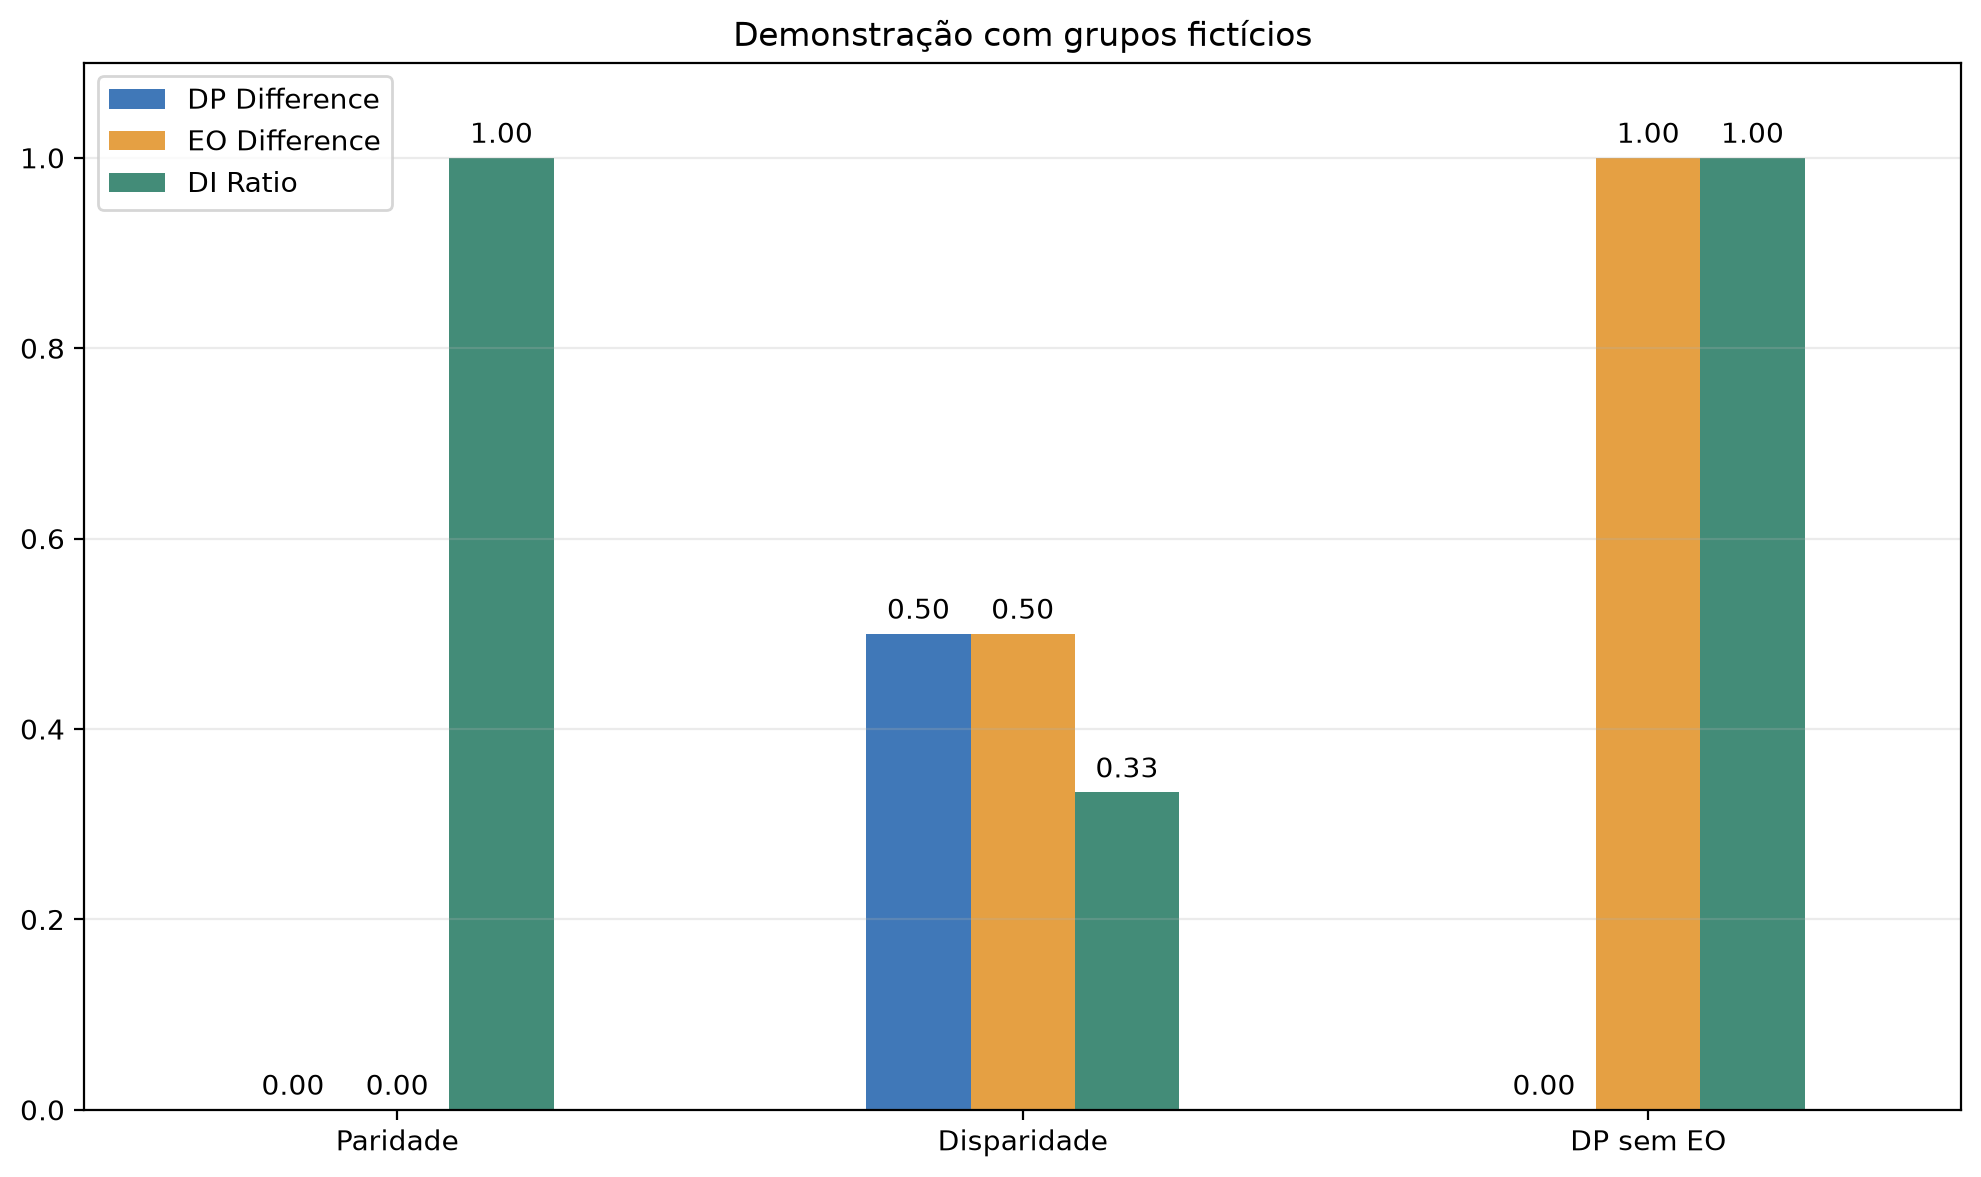

In [7]:
cenarios = json.loads(
    (OUTPUT / "cenarios_sinteticos.json").read_text(
        encoding="utf-8"
    )
)["cenarios"]

display(pd.DataFrame([
    {
        "Cenario": nome,
        "DP": resultado["demographic_parity_difference"],
        "EO": resultado["equal_opportunity_difference"],
        "DI": resultado["disparate_impact_ratio"],
    }
    for nome, resultado in cenarios.items()
]).round(4))

display(Image(filename=str(
    OUTPUT / "03_cenarios_sinteticos.png"
)))


## 8. Contexto socioeconomico territorial

Mapas produzidos na metodologia geoespacial da Sprint 05.

Os indicadores territoriais nao representam atributos
individuais dos contribuintes.


01_renda_territorial_qualificada.png


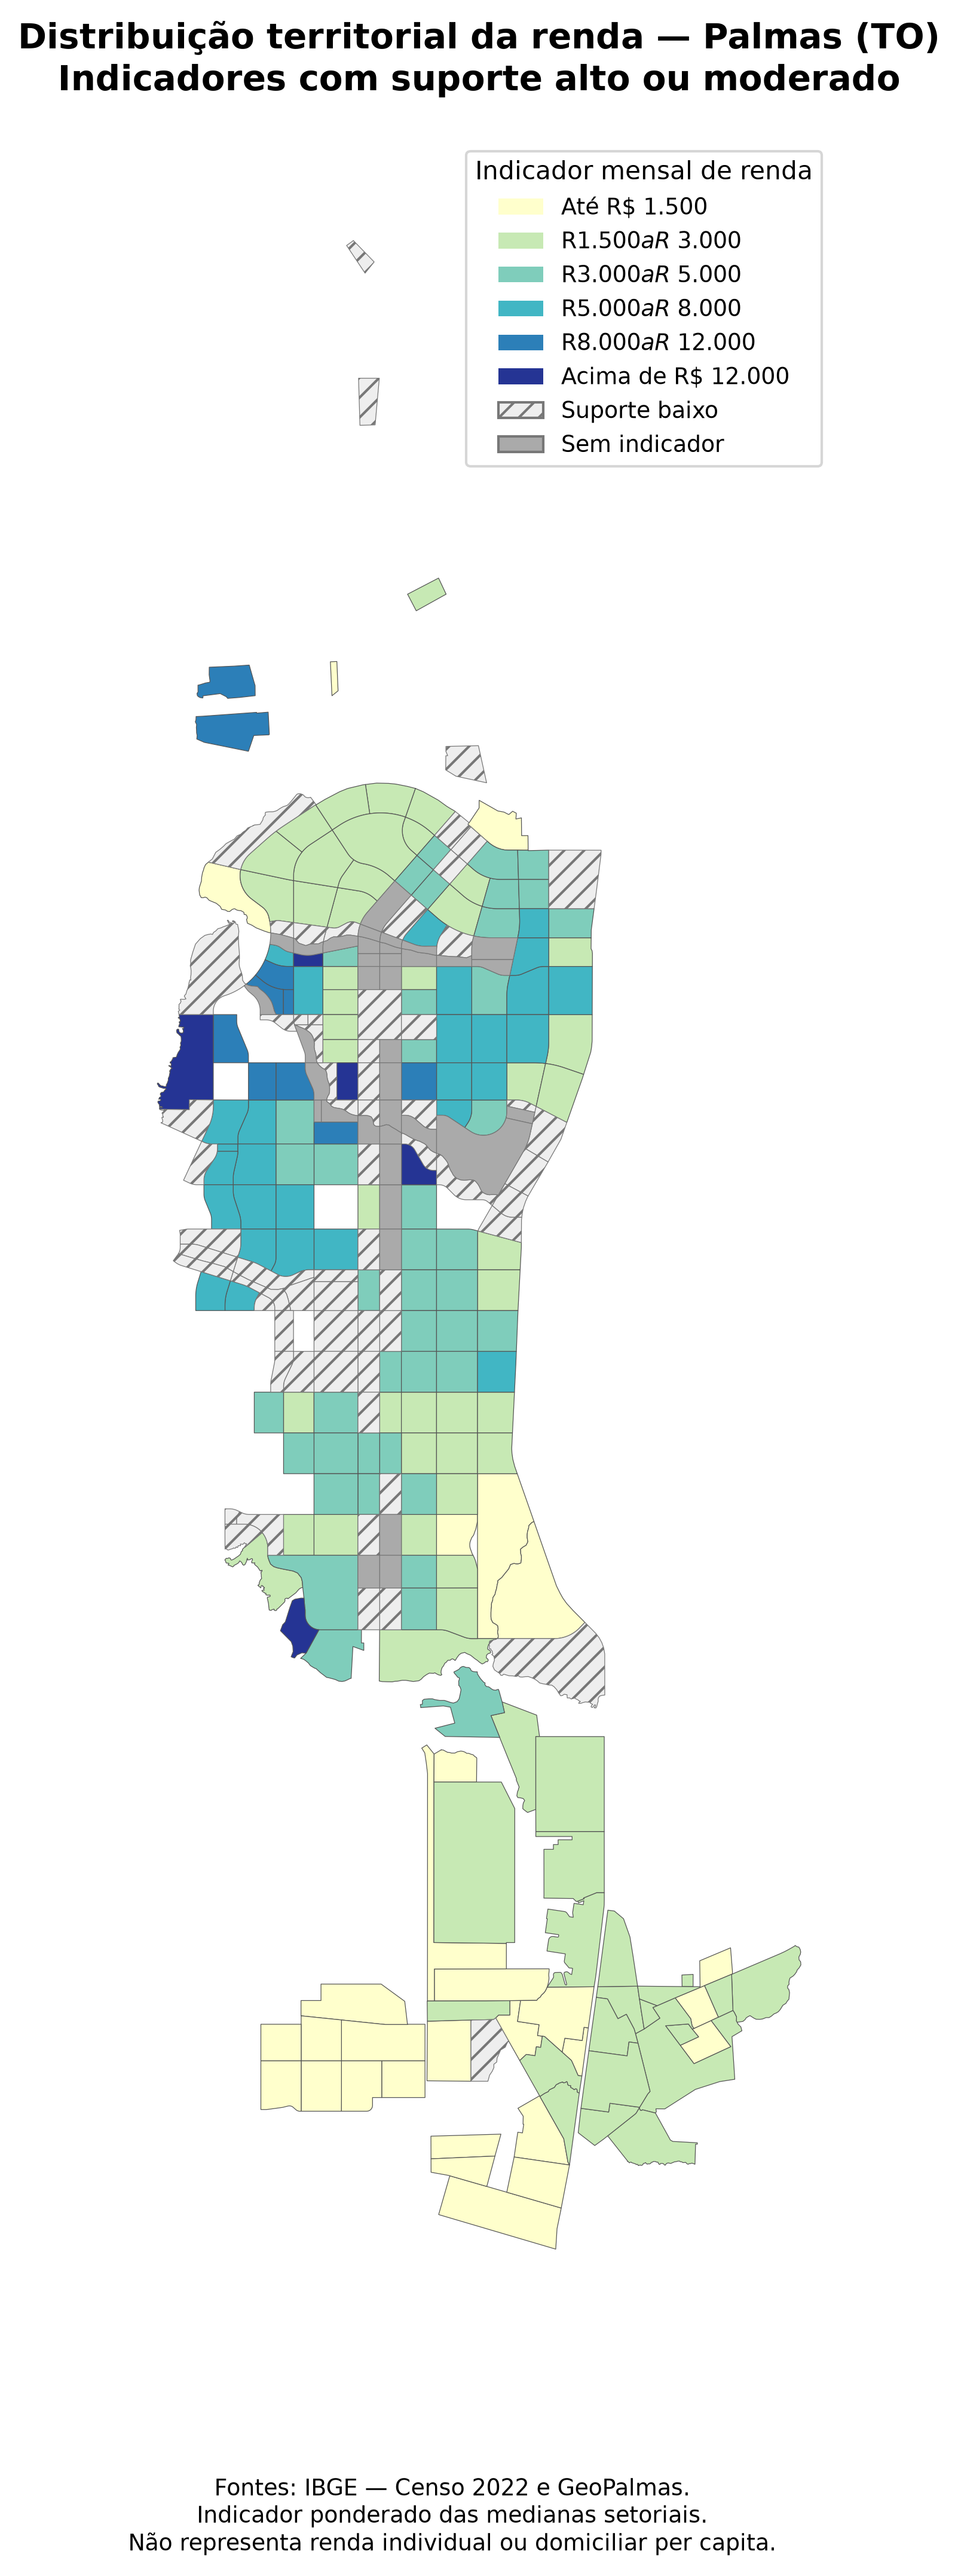

02_suporte_analitico.png


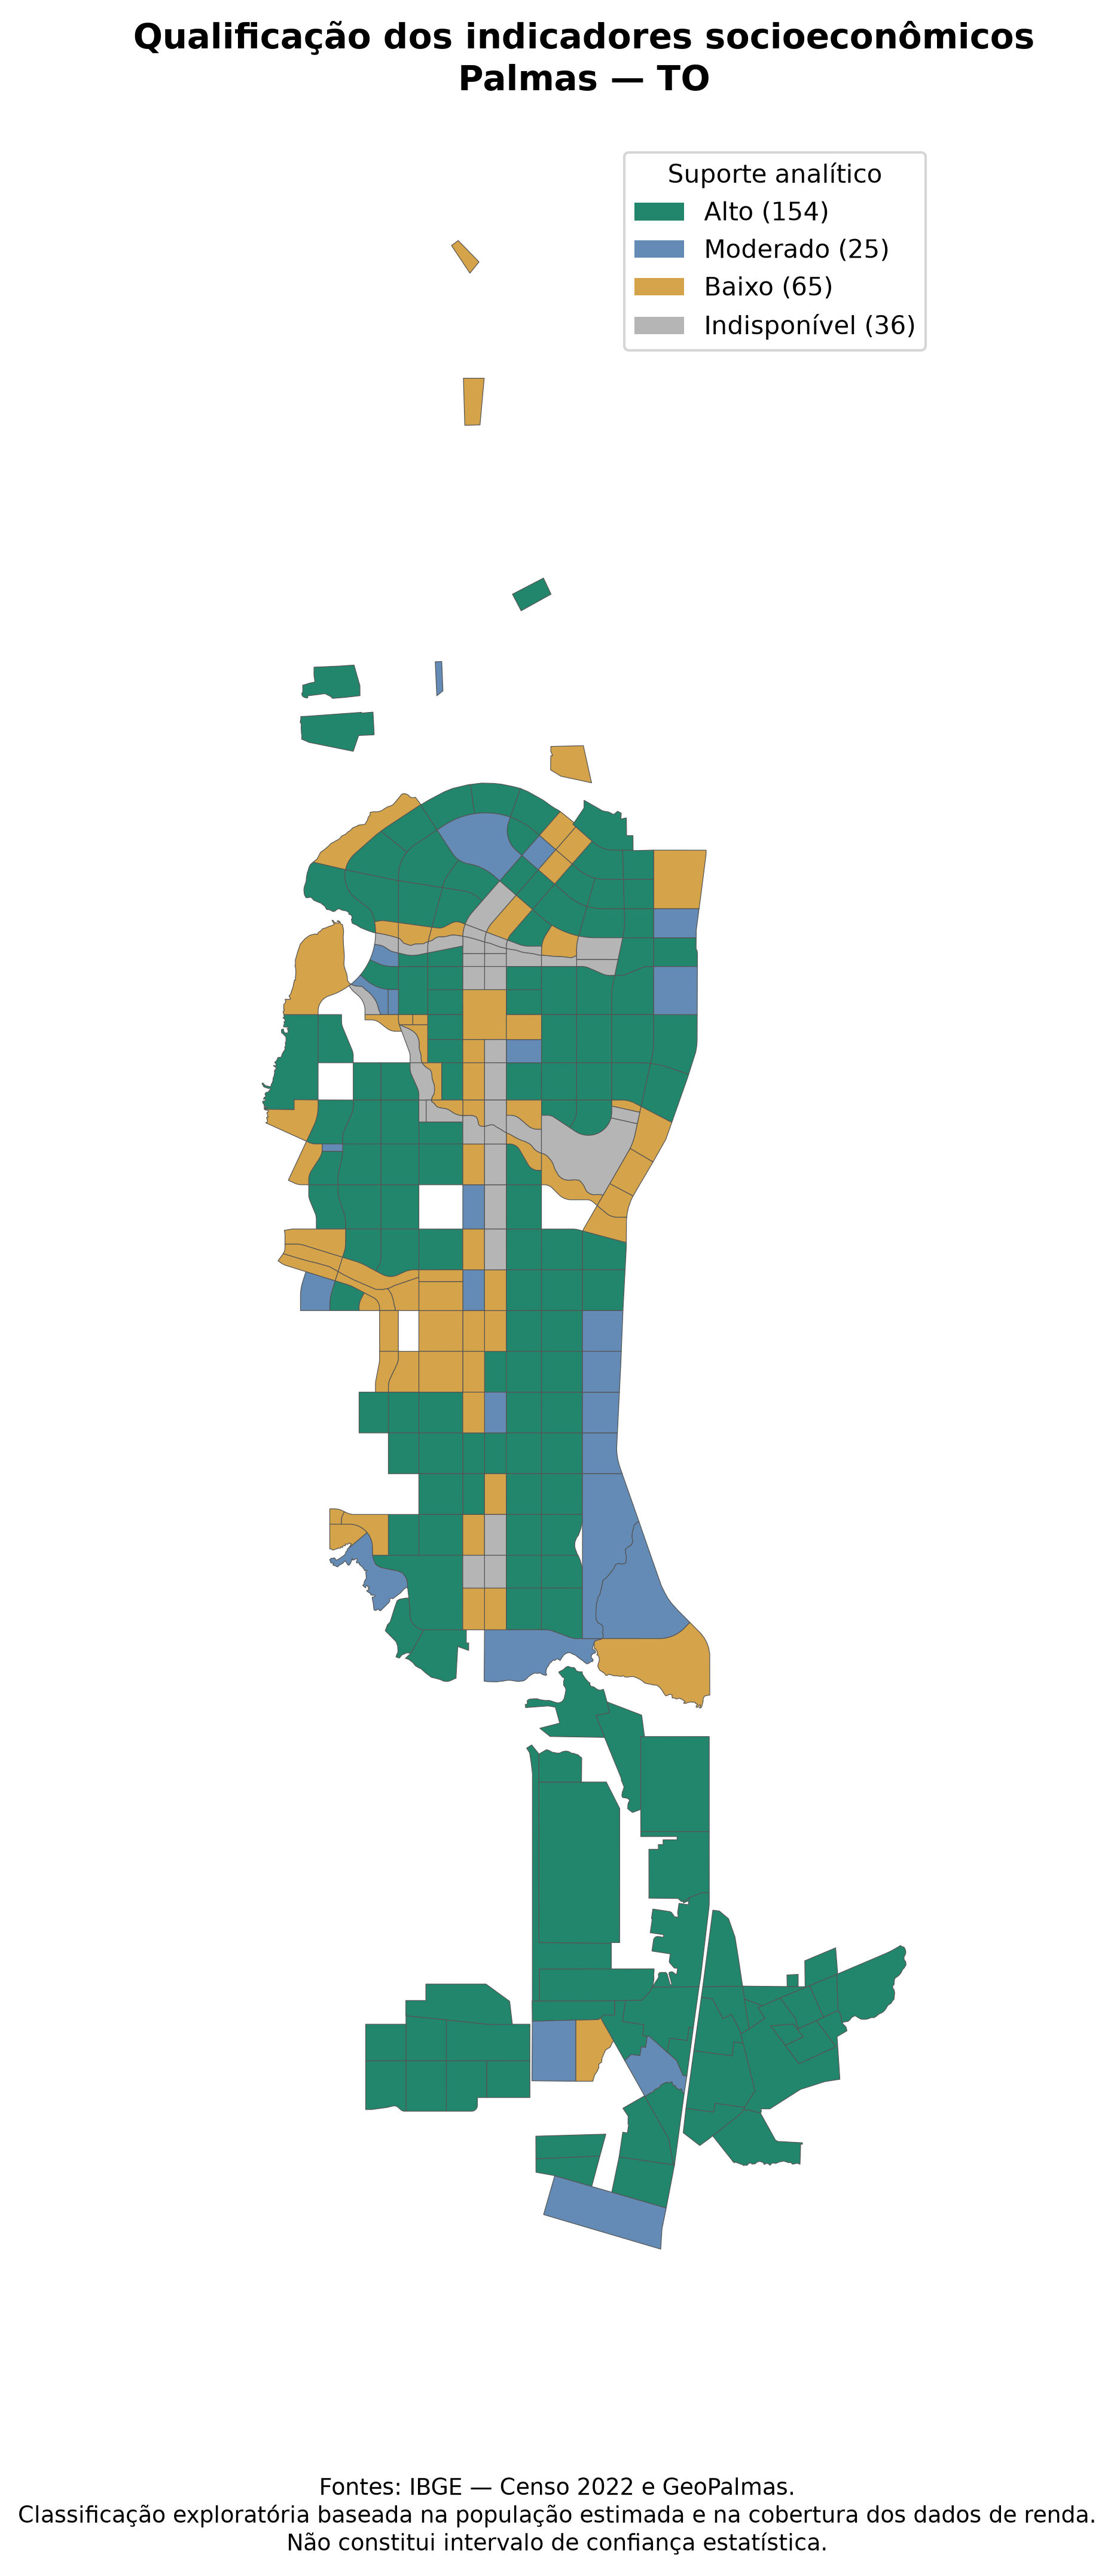

03_densidade_demografica.png


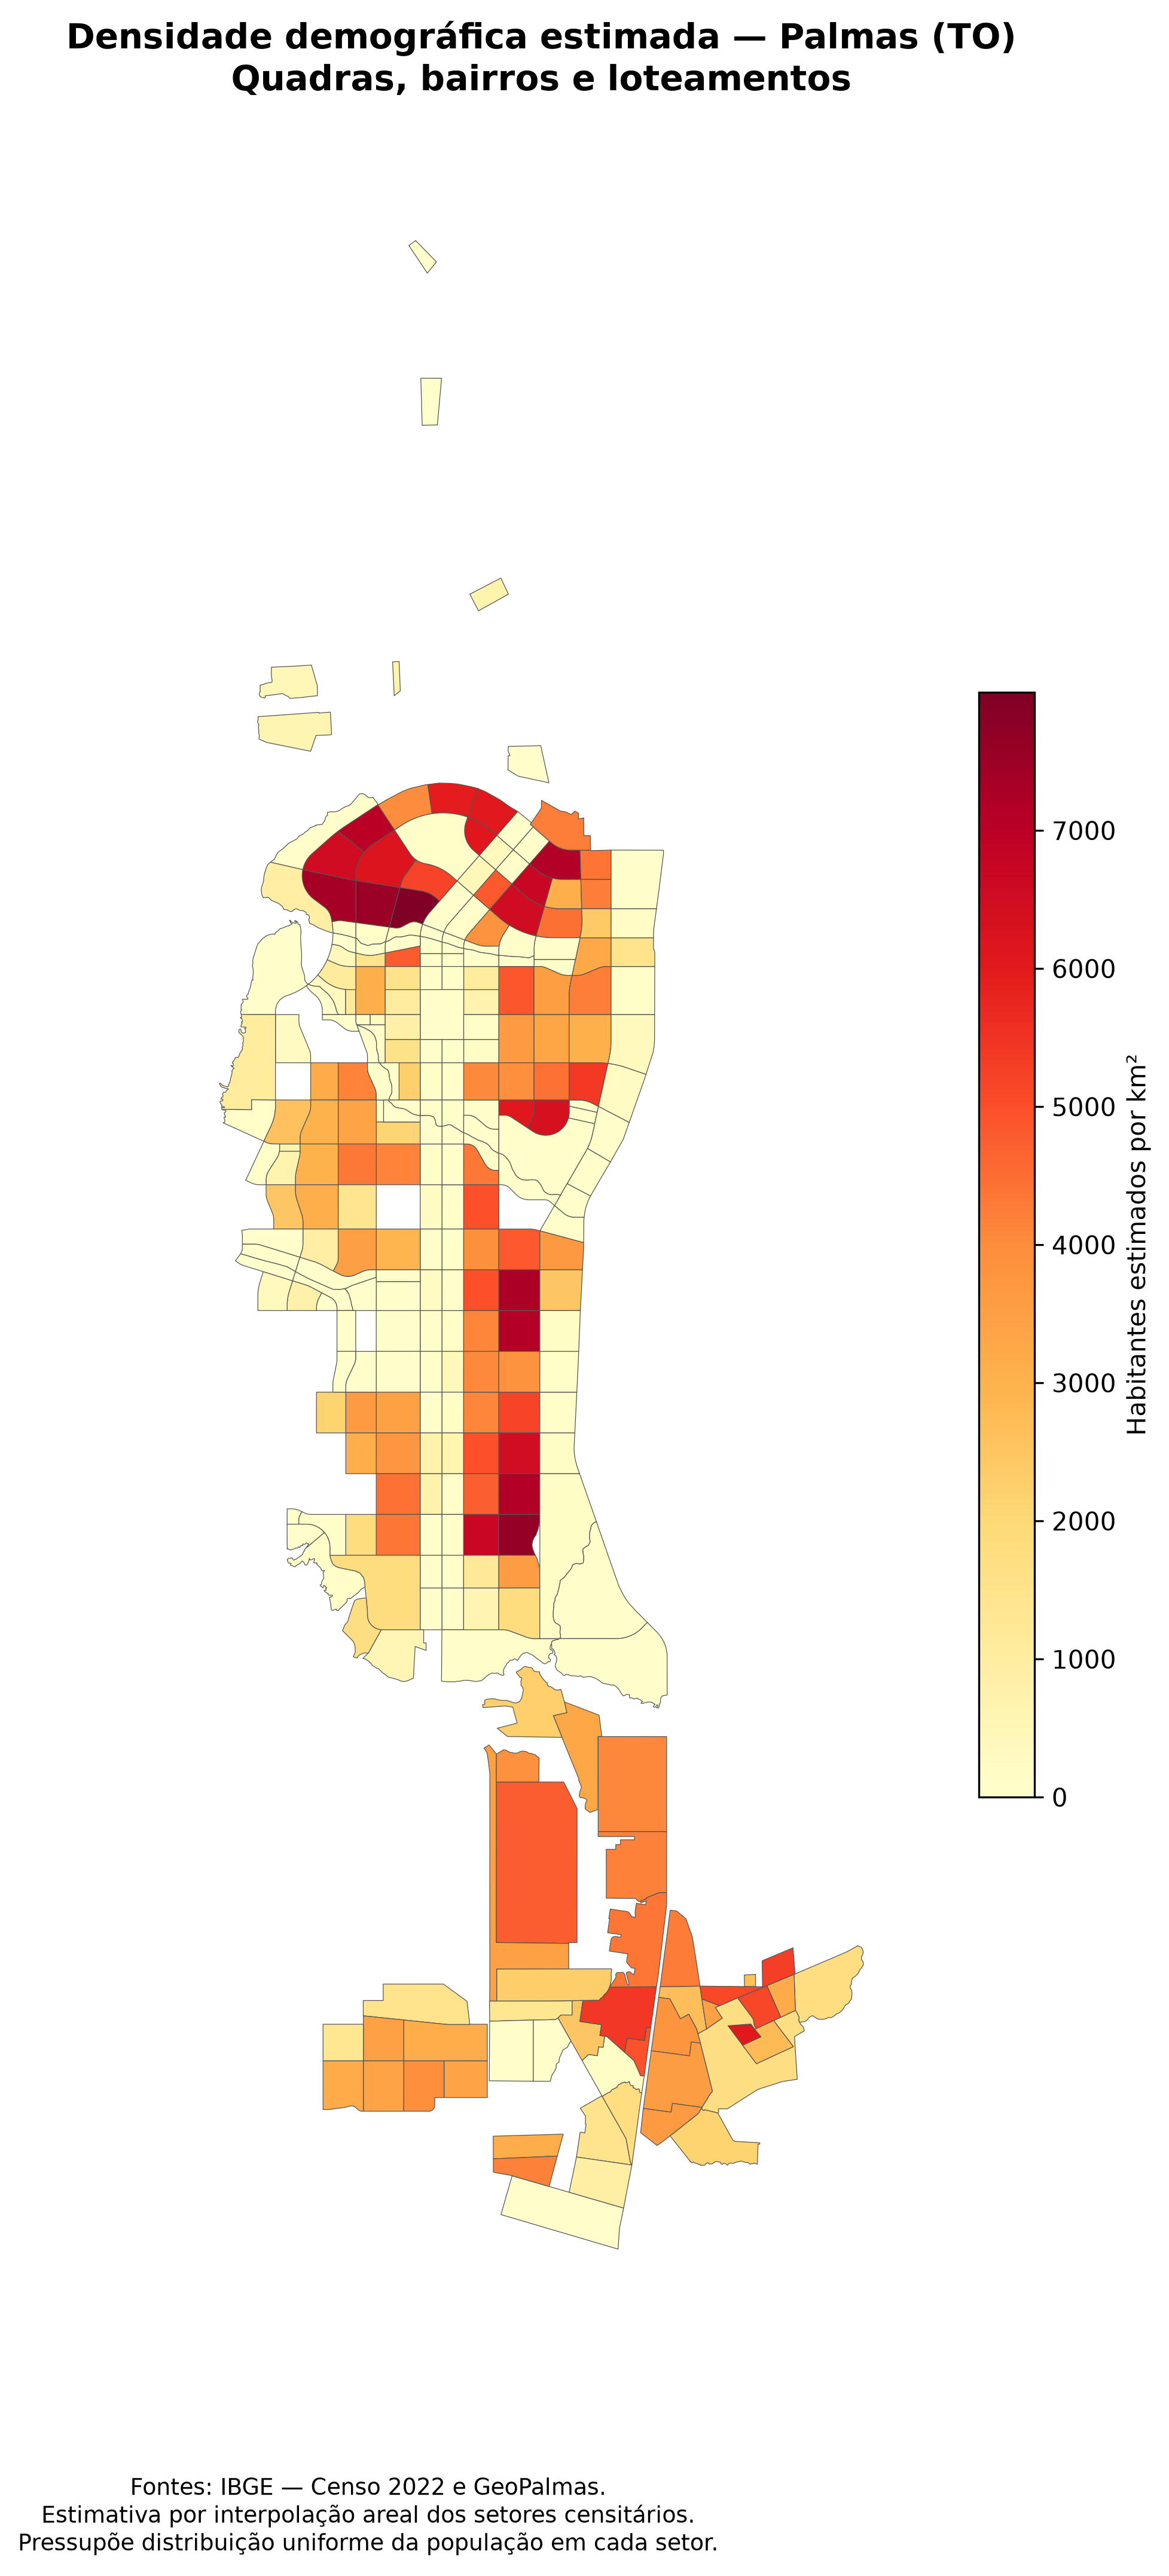

In [8]:
for arquivo in sorted(
    (ROOT / "docs/mapas").glob("*.png")
):
    print(arquivo.name)
    display(Image(filename=str(arquivo), width=850))


## 9. Validacao automatizada

In [9]:
processo = subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests/test_fairness.py",
        "--cov=src.governance.fairness",
        "--cov-branch",
        "--cov-report=term-missing",
        "-q",
    ],
    cwd=ROOT,
    capture_output=True,
    text=True,
    encoding="utf-8",
    env={**__import__("os").environ, "PYTHONUTF8": "1"},
)

print(processo.stdout)

if processo.returncode != 0:
    raise RuntimeError(processo.stderr)


...........................                                              [100%]
=============================== tests coverage ================================
______________ coverage: platform win32, python 3.12.10-final-0 _______________

Name                         Stmts   Miss Branch BrPart  Cover   Missing
------------------------------------------------------------------------
src\governance\fairness.py      39      0     16      0   100%
------------------------------------------------------------------------
TOTAL                           39      0     16      0   100%
27 passed in 0.66s



## 10. Limitacoes e conclusao

- Os alvos dos modelos sao sinteticos.
- Valor e idade da divida nao sao atributos demograficos.
- Nao existe vinculacao individual validada com o Censo.
- Grupos temporais apresentam forte desequilibrio amostral.
- Paridade estatistica nao implica ausencia de discriminacao.
- Cobertura de codigo nao comprova justica algoritmica.
- A protecao ao IPTU Social deve permanecer independente
  dos resultados dos modelos.
- Decisoes administrativas exigem fontes oficiais,
  validacao juridica e revisao humana.

A equidade demografica real permanece nao determinada.
